# Big West Predictor | 2019–2026


In [1]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path('../data/processed')

In [2]:
results = pd.read_csv(DATA_DIR / 'bigwest_2019_2026_results.csv', dtype={'athlete_id': 'Int64'})
team_scores = pd.read_csv(DATA_DIR / 'bigwest_2021_2026_team_scores.csv')
roster = pd.read_csv(DATA_DIR / 'bigwest_roster.csv', dtype={'athlete_id': 'Int64'})
regular_season = pd.read_csv(DATA_DIR / 'regular_season.csv', dtype={'athlete_id': 'Int64'})
national_rank = pd.read_csv(DATA_DIR / 'national_event_ranking.csv')

results_2021 = results[results['meet_year'] == 2021]
results_2021.head()

,athlete_id,athlete_name,team,meet_name,meet_year,gender,event,mark,mark_unit,place,wind,event_type,points,temp,precip_in,humidity_max
3937,7718526,Garrett Reynolds,UC Santa Barbara,2021 Big West Outdoor Track & Field Championships,2021,men,"Men's 10,000 Meters",32:08.29,seconds,1.0,NaN,track,10.0,70.1,0.02,89.2
3938,6476444,Brian Schulz,UC Santa Barbara,2021 Big West Outdoor Track & Field Championships,2021,men,"Men's 10,000 Meters",32:08.46,seconds,2.0,NaN,track,8.0,70.1,0.02,89.2
3939,6452239,Jake Ritter,Cal Poly,2021 Big West Outdoor Track & Field Championships,2021,men,"Men's 10,000 Meters",32:09.21,seconds,3.0,NaN,track,6.0,70.1,0.02,89.2
3940,7384663,Spencer Thurman,Cal Poly,2021 Big West Outdoor Track & Field Championships,2021,men,"Men's 10,000 Meters",32:12.52,seconds,4.0,NaN,track,5.0,70.1,0.02,89.2
3941,5471935,Arman Irani,UC Riverside,2021 Big West Outdoor Track & Field Championships,2021,men,"Men's 10,000 Meters",32:17.28,seconds,5.0,NaN,track,4.0,70.1,0.02,89.2


## 2021: Predicting championship marks from regular-season marks

For each athlete's championship event, we build five features from their 2021 regular-season marks in that same event (outdoor meets before the championships on May 12, 2021 only; indoor marks aren't comparable, and 2021 had no indoor season anyway). Then we fit a one-feature linear regression for each feature and score it with R².

If an athlete has several marks at one meet (e.g. prelim + final), we keep their best mark from that meet.

| Feature | Definition |
|---|---|
| Season median | Median mark across the season's meets |
| Mean of last 3 meets | Average of the last 3 meets before the championships |
| Most recent meet | The last meet before the championships |
| Wind-legal season best | Best mark with wind ≤ +2.0 m/s. Only differs from season best in the 100, 200, hurdles, long jump and triple jump. Marks with no wind reading don't count as legal. |
| Season best | Best mark of the season |

**Target:** the athlete's championship mark from `results` (their final if they made it, otherwise their prelim). Relays and multi-events are excluded, as are DNF, FOUL, NH, etc. A championship mark more than 50% worse than the athlete's own season best is treated like a DNF too (e.g. injured and jogged in). In 2021 that's one race: a 1:40.56 in the men's 400m final from a runner who ran 48.28 in the prelims.

**Two R² scores** (both use the same athletes; they differ in *which differences* they try to explain):
- **Raw R²** fits one line across every event. It comes out near 1.0 for every feature because events are on different scales (a 10k takes ~30 minutes, a 100m ~11 seconds), so it doesn't tell the features apart.
- **Within-event R²** first converts each mark to "standard deviations from the event average" (same gender + event). It measures how well a feature predicts who does better *within* an event. **Use this one to compare features.**

In [3]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# First day of each Big West Championships; only regular-season marks before it count
CHAMPS_START = {2019: '2019-05-10', 2021: '2021-05-12', 2022: '2022-05-13', 2023: '2023-05-12', 2024: '2024-05-10',
                2025: '2025-05-16', 2026: '2026-05-15'}  # 2026: main meet (multi-events were May 8-9)
WIND_EVENTS = {'100', '200', '100H', '110H', 'LJ', 'TJ'}
WIND_LIMIT = 2.0  # m/s
MIN_ATHLETES_PER_EVENT = 5  # need a few athletes to standardize within an event
MAX_OFF_SEASON_BEST = 0.5  # championship marks >50% worse than the athlete's season best aren't a real race
WEATHER = ['temp', 'precip_in', 'humidity_max']  # °F daily high, inches of rain, max relative humidity (%)

# Championship event names -> regular-season event codes
EVENT_CODES = {
    '100 Meters': '100', '200 Meters': '200', '400 Meters': '400', '800 Meters': '800',
    '1500 Meters': '1500', '5000 Meters': '5000', '10,000 Meters': '10,000',
    '100 Hurdles': '100H', '110 Hurdles': '110H', '400 Hurdles': '400H',
    '3000 Steeplechase': '3000S',
    'High Jump': 'HJ', 'Pole Vault': 'PV', 'Long Jump': 'LJ', 'Triple Jump': 'TJ',
    'Shot Put': 'SP', 'Discus': 'DT', 'Hammer': 'HT', 'Javelin': 'JT',
}

FEATURES = {
    'median_mark': 'Season median',
    'last3_mean': 'Mean of last 3 meets',
    'most_recent': 'Most recent meet',
    'wind_legal_sb': 'Wind-legal season best',
    'season_best': 'Season best',
}

# Events held only indoors / only outdoors, used to tell indoor meets apart
INDOOR_ONLY_EVENTS = {'60', '60H', 'WT', 'Pent'}
OUTDOOR_ONLY_EVENTS = {'100', '100H', '110H', '400H', '3000S', '10,000', 'DT', 'HT', 'JT', '4x100', 'Dec'}


def to_number(mark):
    """'10.74' -> 10.74, '3:44.68' -> 224.68, '7.45m' -> 7.45, 'DNF'/'FOUL' -> NaN."""
    text = str(mark).strip().removesuffix('m')
    try:
        return sum(float(part) * 60**i for i, part in enumerate(reversed(text.split(':'))))
    except ValueError:
        return np.nan


# A meet is indoor if "Indoor" is in its name, or it has no outdoor-only events
# and either has indoor-only events or is in January/February.
meet_events = regular_season.groupby(['meet_name', 'meet_start_date'])['event']
has_outdoor_event = meet_events.transform(lambda e: e.isin(OUTDOOR_ONLY_EVENTS).any())
has_indoor_event = meet_events.transform(lambda e: e.isin(INDOOR_ONLY_EVENTS).any())
jan_or_feb = pd.to_datetime(regular_season['meet_start_date']).dt.month <= 2
regular_season['is_indoor'] = (regular_season['meet_name'].str.contains('indoor', case=False)
                               | (~has_outdoor_event & (has_indoor_event | jan_or_feb)))


def season_features(g):
    best = 'min' if g['lower_is_better'].iat[0] else 'max'
    # One mark per meet (the athlete's best there), in date order
    per_meet = g.groupby(['date', 'meet_name'])['mark_num'].agg(best).sort_index()
    legal = g.loc[g['wind_legal'], 'mark_num']
    return pd.Series({
        'n_meets': len(per_meet),
        'median_mark': per_meet.median(),
        'last3_mean': per_meet.tail(3).mean(),
        'most_recent': per_meet.iloc[-1],
        'wind_legal_sb': legal.agg(best) if len(legal) else np.nan,
        'season_best': per_meet.agg(best),
    })


def build_model_data(year):
    """One row per athlete-event at that year's championships, with regular-season features."""
    # Target: championship mark (individual track and field events)
    champs = results[(results['meet_year'] == year)
                     & results['event_type'].isin(['track', 'field'])].copy()
    champs['gender'] = champs['gender'].str.capitalize()
    champs['event_code'] = (champs['event']
                            .str.replace(r"^(?:Men|Women)'s ", '', regex=True)
                            .map(EVENT_CODES))
    assert champs['event_code'].notna().all(), 'Unmapped championship event'
    champs['final_mark'] = champs['mark'].map(to_number)
    champs = champs.dropna(subset=['athlete_id', 'final_mark'])  # drops DNF, FOUL, NH, ...
    # Championship weather: one value per meet (champ_temp, champ_precip_in, champ_humidity_max)
    champs = champs.rename(columns={col: f'champ_{col}' for col in WEATHER})

    # Outdoor regular-season marks from before the championships
    season = regular_season[(regular_season['year'] == year) & ~regular_season['is_indoor']].copy()
    season['date'] = pd.to_datetime(season['meet_start_date'])
    season = season[season['date'] < pd.Timestamp(CHAMPS_START[year])]
    season = season.rename(columns={'event': 'event_code'})
    season['gender'] = season['gender'].str.capitalize()  # regular_season.csv uses 'men'/'women'
    season['mark_num'] = season['mark'].map(to_number)
    season = season.dropna(subset=['mark_num'])
    season['lower_is_better'] = season['event_type'].eq('track')
    season['wind_legal'] = ~season['event_code'].isin(WIND_EVENTS) | (season['wind'] <= WIND_LIMIT)

    keys = ['athlete_id', 'gender', 'event_code']
    features = season.groupby(keys).apply(season_features, include_groups=False).reset_index()

    # Keep athletes with every feature, so all five models use the same rows
    data = champs.merge(features, on=keys, how='inner').dropna(subset=list(FEATURES))
    assert data['champ_temp'].notna().all(), 'Missing championship weather'

    # Treat marks far off the athlete's own season best like a DNF (e.g. injured and jogged in)
    off_best = np.where(data['event_type'] == 'track',
                        data['final_mark'] / data['season_best'] - 1,
                        1 - data['final_mark'] / data['season_best'])
    not_a_race = off_best > MAX_OFF_SEASON_BEST
    if not_a_race.any():
        print(f'{year}: dropped as not a real race:')
        print(data.loc[not_a_race, ['event', 'athlete_name', 'final_mark', 'season_best']].to_string(index=False))
    data = data[~not_a_race]

    event_size = data.groupby('event')['athlete_id'].transform('size')
    data = data[event_size >= MIN_ATHLETES_PER_EVENT].copy()
    print(f'{year}: {len(champs)} championship marks -> {len(data)} with regular-season '
          f'marks in the same event {data["event_type"].value_counts().to_dict()}')
    return data


model_data = build_model_data(2021)
model_data[['athlete_name', 'gender', 'event_code', 'final_mark', 'n_meets', *FEATURES]].head()

2021: dropped as not a real race:
           event    athlete_name  final_mark  season_best
Men's 400 Meters Marcel Espinoza      100.56        47.47
2021: 580 championship marks -> 536 with regular-season marks in the same event {'track': 279, 'field': 257}


,athlete_name,gender,event_code,final_mark,n_meets,median_mark,last3_mean,most_recent,wind_legal_sb,season_best
3,Benjamin Goodwin,Men,100,10.67,4.0,10.855,10.806667,10.67,10.67,10.67
4,Chineme Allison,Men,100,10.68,6.0,10.705,10.650000,10.52,10.65,10.52
5,Rasaun House,Men,100,10.71,4.0,10.800,10.816667,10.84,10.76,10.75
6,Tyler Esteves,Men,100,10.71,2.0,10.660,10.660000,10.55,10.55,10.55
7,Kent Harris,Men,100,10.77,2.0,10.820,10.820000,10.77,10.77,10.77


In [4]:
def zscore_within_event(df, col):
    """Standard deviations from the average for the same gender + event."""
    grp = df.groupby(['gender', 'event_code'])[col]
    return (df[col] - grp.transform('mean')) / grp.transform('std')


def fit_r2(x, y):
    X = np.asarray(x).reshape(-1, 1)
    model = LinearRegression().fit(X, y)
    return r2_score(y, model.predict(X))


for col in [*FEATURES, 'final_mark']:
    model_data[f'{col}_z'] = zscore_within_event(model_data, col)

subsets = {
    'All': model_data,
    'Track': model_data[model_data['event_type'] == 'track'],
    'Field': model_data[model_data['event_type'] == 'field'],
}

rows = []
for feature, label in FEATURES.items():
    for subset, df in subsets.items():
        rows.append({
            'feature': label,
            'subset': subset,
            'within_event_r2': fit_r2(df[f'{feature}_z'], df['final_mark_z']),
            'raw_r2': fit_r2(df[feature], df['final_mark']),
        })
r2_results = pd.DataFrame(rows)

within_r2 = r2_results.pivot(index='feature', columns='subset', values='within_event_r2')[list(subsets)]
raw_r2 = r2_results.pivot(index='feature', columns='subset', values='raw_r2')[list(subsets)]

print('Rows per subset:', {name: len(df) for name, df in subsets.items()})
print('Best feature per subset:', within_r2.idxmax().to_dict())
print('\nWithin-event R² (use this to compare features)')
display(within_r2.sort_values('All', ascending=False).round(3))
print('Raw R² (one line across all events; near 1.0 because of event scale differences)')
display(raw_r2.round(4))

Rows per subset: {'All': 536, 'Track': 279, 'Field': 257}
Best feature per subset: {'All': 'Season best', 'Track': 'Wind-legal season best', 'Field': 'Mean of last 3 meets'}

Within-event R² (use this to compare features)


subset,All,Track,Field
feature,,,
Season best,0.622,0.635,0.607
Season median,0.619,0.626,0.612
Wind-legal season best,0.618,0.637,0.597
Mean of last 3 meets,0.608,0.601,0.617
Most recent meet,0.570,0.579,0.560


Raw R² (one line across all events; near 1.0 because of event scale differences)


subset,All,Track,Field
feature,,,
Mean of last 3 meets,0.9993,0.9991,0.9910
Most recent meet,0.9993,0.9991,0.9884
Season best,0.9993,0.9992,0.9922
Season median,0.9993,0.9991,0.9913
Wind-legal season best,0.9993,0.9992,0.9922


### R² for each event on its own

Same idea as within-event R², but with a separate line fit for each event (e.g. men's 100m season best → men's 100m championship mark). The combined numbers above are roughly a weighted blend of these.

Check `n` before reading too much into a row. With ~15 athletes, one unusual race can move an event's R² a lot.

In [5]:
labels = list(FEATURES.values())

rows = []
for (event_type, event), df in model_data.groupby(['event_type', 'event']):
    row = {'event_type': event_type, 'event': event, 'n': len(df)}
    for feature, label in FEATURES.items():
        row[label] = fit_r2(df[feature], df['final_mark'])
    rows.append(row)

per_event_r2 = (pd.DataFrame(rows)
                .sort_values(['event_type', 'event'], ascending=[False, True])
                .set_index(['event_type', 'event']))

# Best feature per event. Ties are listed together: outside the wind events,
# wind-legal season best and season best are the same number.
scores = per_event_r2[labels]
is_best = scores.ge(scores.max(axis=1) - 1e-9, axis=0)
per_event_r2['Best feature'] = is_best.apply(lambda r: ' = '.join(r.index[r]), axis=1)

per_event_summary = pd.DataFrame({
    'Median R² (all events)': scores.median(),
    'Median R² (track)': scores.loc['track'].median(),
    'Median R² (field)': scores.loc['field'].median(),
    'Events where best (ties count for each)': is_best.sum(),
})

display(per_event_r2.round(2))
display(per_event_summary.round(3))

n  Season median  Mean of last 3 meets  \
event_type event                                                                
track      Men's 100 Meters           14           0.75                  0.82   
           Men's 110 Hurdles          13           0.71                  0.58   
           Men's 1500 Meters          15           0.36                  0.34   
           Men's 200 Meters           16           0.64                  0.60   
           Men's 3000 Steeplechase    12           0.70                  0.63   
           Men's 400 Hurdles          12           0.81                  0.77   
           Men's 400 Meters           13           0.75                  0.52   
           Men's 5000 Meters          22           0.24                  0.24   
           Men's 800 Meters           14           0.66                  0.73   
           Women's 10,000 Meters       5           0.62                  0.62   
           Women's 100 Hurdles        15           0.71                  0.57   
           Women's 100 Meters         16           0.82                  0.81   
           Women's 1500 Meters        21           0.52                  0.55   
           Women's 200 Meters         13           0.50                  0.41   
           Women's 3000 Steeplechase  11           0.85                  0.82   
           Women's 400 Hurdles        11           0.72                  0.54   
           Women's 400 Meters         14           0.62                  0.69   
           Women's 5000 Meters        24           0.68                  0.72   
           Women's 800 Meters         18           0.80                  0.88   
field      Men's Discus               18           0.76                  0.77   
           Men's Hammer               17           0.80                  0.76   
           Men's High Jump            11           0.92                  0.88   
           Men's Javelin              13           0.39                  0.39   
           Men's Long Jump            22           0.35                  0.34   
           Men's Pole Vault           12           0.57                  0.67   
           Men's Shot Put             17           0.67                  0.60   
           Men's Triple Jump          14           0.73                  0.75   
           Women's Discus             23           0.60                  0.65   
           Women's Hammer             20           0.62                  0.63   
           Women's High Jump          13           0.74                  0.75   
           Women's Javelin            12           0.18                  0.17   
           Women's Long Jump          15           0.67                  0.72   
           Women's Pole Vault         19           0.68                  0.71   
           Women's Shot Put           20           0.65                  0.60   
           Women's Triple Jump        11           0.76                  0.82   

                                      Most recent meet  \
event_type event                                         
track      Men's 100 Meters                       0.63   
           Men's 110 Hurdles                      0.70   
           Men's 1500 Meters                      0.24   
           Men's 200 Meters                       0.53   
           Men's 3000 Steeplechase                0.54   
           Men's 400 Hurdles                      0.53   
           Men's 400 Meters                       0.37   
           Men's 5000 Meters                      0.40   
           Men's 800 Meters                       0.73   
           Women's 10,000 Meters                  0.62   
           Women's 100 Hurdles                    0.80   
           Women's 100 Meters                     0.78   
           Women's 1500 Meters                    0.45   
           Women's 200 Meters                     0.43   
           Women's 3000 Steeplechase              0.81   
           Women's 400 Hurdles                    0.49 

,Median R² (all events),Median R² (track),Median R² (field),Events where best (ties count for each)
Season median,0.675,0.705,0.671,8
Mean of last 3 meets,0.650,0.621,0.692,9
Most recent meet,0.621,0.621,0.630,7
Wind-legal season best,0.631,0.671,0.623,11
Season best,0.631,0.671,0.628,13


## Weather effect, learned from the regular season

To learn how weather changes performance, we use the **regular season**, not the championships. There are only 7 championships, so 7 weather readings, and any weather effect fit on them can't be told apart from "that year went badly". The regular season has ~250 outdoor meets with temperatures from 50 to 98 °F.

**Method:** for each athlete, event and season, we measure every meet's mark as **% worse than that athlete's season best** (positive = worse; one mark per meet, outdoor, before the championships, athletes with 3+ meets). Then, comparing each athlete only with themselves, we fit:

% worse than season best ~ temperature band + precipitation + max humidity + day of year

- **Comparing each athlete with themselves** (athlete-event-season fixed effects) removes who the athlete is and how good they are.
- **Day of year** absorbs normal improvement through the season (meets get warmer as athletes get fitter, which would otherwise look like a heat effect).
- **Temperature in bands** (vs a 60–70 °F day), because heat helps some events and hurts others: sprinters and jumpers get faster in the heat, distance runners get slower.
- **Fit separately for each event group** (sprints, hurdles, distance, jumps, throws).
- **Training years only** (2019, 2021–2025). Standard errors are clustered by meet.

**Using it at the championships:** for each athlete, the model gives the expected change in their mark from the weather at the meet where they set their season best to the weather at the championships. Nothing about weather is fit on championship results. This gives two weather features:
- **Weather-adjusted season best:** every regular-season mark is moved to that year's championship weather, then we take the best.
- **Weather shift:** the expected % change from the season-best meet's weather to the championship weather (positive = the championship weather should make them worse).

In [6]:
from scipy import stats
from statsmodels.regression.linear_model import OLS  # statsmodels.formula.api fails to import with this scipy version
from tqdm.auto import tqdm

TRAIN_YEARS, TEST_YEAR = [2019, 2021, 2022, 2023, 2024, 2025], 2026  # no 2020 championships (COVID)
GROUP = {'100': 'Sprints', '200': 'Sprints', '400': 'Sprints',
         '100H': 'Hurdles', '110H': 'Hurdles', '400H': 'Hurdles',
         '800': 'Distance', '1500': 'Distance', '5000': 'Distance', '10,000': 'Distance', '3000S': 'Distance',
         'HJ': 'Jumps', 'PV': 'Jumps', 'LJ': 'Jumps', 'TJ': 'Jumps',
         'SP': 'Throws', 'DT': 'Throws', 'HT': 'Throws', 'JT': 'Throws'}
TEMP_BINS = [-np.inf, 60, 70, 80, 85, np.inf]
TEMP_LABELS = ['<60 °F', '60–70 °F', '70–80 °F', '80–85 °F', '85+ °F']
REF_BAND = '60–70 °F'
WX_TERMS = [band for band in TEMP_LABELS if band != REF_BAND] + ['precip_in', 'humidity_max']
MIN_MEETS = 3            # athlete-event-seasons with fewer meets don't say much about meet-to-meet changes
MAX_PCT_OFF = 20         # marks >20% off the athlete's own season best are injuries / jog-ins, not weather
SEASON_KEYS = ['athlete_id', 'year', 'event_code']


def per_meet_marks(years):
    """Each athlete's best mark per event at each outdoor meet before that year's championships, with the meet's weather.

    Same marks as build_model_data uses for the season best. `better` is oriented so higher = better."""
    rs = regular_season[regular_season['year'].isin(years) & ~regular_season['is_indoor']
                        & regular_season['event'].isin(GROUP)].copy()
    rs['date'] = pd.to_datetime(rs['meet_start_date'])
    rs = rs[rs['date'] < pd.to_datetime(rs['year'].map(CHAMPS_START))]
    rs['mark_num'] = rs['mark'].map(to_number)
    rs = rs.dropna(subset=['mark_num'])
    rs['better'] = np.where(rs['event_type'] == 'track', -rs['mark_num'], rs['mark_num'])
    marks = (rs.groupby(['athlete_id', 'gender', 'year', 'event', 'date', 'meet_name'])
             .agg(better=('better', 'max'), **{col: (col, 'first') for col in WEATHER})
             .reset_index().rename(columns={'event': 'event_code'}))
    assert marks['temp'].notna().all(), 'Outdoor meet without weather'
    marks['gender'] = marks['gender'].str.capitalize()
    marks['group'] = marks['event_code'].map(GROUP)
    return marks


def weather_terms(df):
    """Temperature band dummies (vs 60–70 °F) + precipitation + humidity."""
    bands = pd.cut(df['temp'], TEMP_BINS, labels=TEMP_LABELS, right=False)
    dummies = pd.get_dummies(bands).astype(float).set_axis(TEMP_LABELS, axis=1)  # plain column labels, not categorical
    return dummies.drop(columns=REF_BAND).join(df[['precip_in', 'humidity_max']])


# Learn the weather effect: training years, each athlete compared with themselves
season_marks = per_meet_marks(TRAIN_YEARS)
season_marks = season_marks[season_marks.groupby(SEASON_KEYS)['better'].transform('size') >= MIN_MEETS].copy()
best = season_marks.groupby(SEASON_KEYS)['better'].transform('max')
season_marks['pct_off_sb'] = (best - season_marks['better']) / best.abs() * 100
season_marks = season_marks[season_marks['pct_off_sb'] < MAX_PCT_OFF]
season_marks['day_of_year'] = season_marks['date'].dt.dayofyear

wx_coef, rows = {}, []
for group, df in tqdm(season_marks.groupby('group'), desc='Fitting weather effects'):
    X = weather_terms(df).assign(day_of_year=df['day_of_year'])
    by_season = [df[k] for k in SEASON_KEYS]
    within = lambda f: f - f.groupby(by_season).transform('mean')  # compare each athlete with themselves
    fit = OLS(within(df['pct_off_sb']), within(X)).fit(
        cov_type='cluster', cov_kwds={'groups': df['meet_name'].astype('category').cat.codes})
    wx_coef[group] = fit.params[WX_TERMS]
    rows.append({'group': group, 'marks': len(df), 'meets': df['meet_name'].nunique(),
                 **{term: fit.params[term] for term in TEMP_LABELS if term != REF_BAND},
                 '+0.1 in rain': fit.params['precip_in'] * 0.1,
                 '+10 pts humidity': fit.params['humidity_max'] * 10,
                 'p (heat 85+)': fit.pvalues['85+ °F']})
wx_coef = pd.DataFrame(wx_coef).T
wx_table = pd.DataFrame(rows).set_index('group')
band_counts = pd.cut(season_marks['temp'], TEMP_BINS, labels=TEMP_LABELS, right=False).value_counts().reindex(TEMP_LABELS)

print('Regular-season marks per temperature band:', band_counts.to_dict())
print(f'Weather effect on % worse than season best (positive = worse), vs a dry {REF_BAND} day, same athlete')
display(wx_table.round(2))


def weather_effect(df):
    """% worse than usual expected from the weather alone (positive = worse), from the regular-season fit."""
    return (weather_terms(df)[WX_TERMS] * wx_coef.loc[df['group']].set_axis(df.index)).sum(axis=1)


champ_weather = results.groupby('meet_year')[WEATHER].first()


def weather_features(year):
    """Weather-adjusted season best and weather shift for each athlete-event in that year's season."""
    marks = per_meet_marks([year])
    at_champs = marks.assign(**champ_weather.loc[year].to_dict())
    marks['shift'] = weather_effect(at_champs) - weather_effect(marks)  # + = championship weather is worse
    marks['better_adj'] = marks['better'] - marks['shift'] / 100 * marks['better'].abs()
    keys = ['athlete_id', 'gender', 'year', 'event_code']
    sb_meet = marks.loc[marks.groupby(keys)['better'].idxmax()].set_index(keys)
    out = pd.DataFrame({
        'season_best_check': sb_meet['better'].abs(),
        'wx_shift': sb_meet['shift'],                      # from the season-best meet's weather to the championships
        'season_best_wx': marks.groupby(keys)['better_adj'].max().abs(),
    })
    return out.reset_index()

Fitting weather effects:   0%|          | 0/5 [00:00<?, ?it/s]

Regular-season marks per temperature band: {'<60 °F': 5093, '60–70 °F': 11153, '70–80 °F': 6641, '80–85 °F': 1320, '85+ °F': 1304}
Weather effect on % worse than season best (positive = worse), vs a dry 60–70 °F day, same athlete


,marks,meets,<60 °F,70–80 °F,80–85 °F,85+ °F,+0.1 in rain,+10 pts humidity,p (heat 85+)
group,,,,,,,,,
Distance,4827,180,0.17,-0.14,-0.08,0.89,-0.02,-0.03,0.00
Hurdles,2896,188,0.16,-0.25,-0.47,-0.70,-0.02,-0.00,0.03
Jumps,5212,187,0.05,-0.28,-0.56,-0.80,0.04,-0.04,0.01
Sprints,5691,189,0.13,-0.16,-0.16,-0.49,0.01,0.04,0.00
Throws,6885,188,0.20,-0.18,-0.83,-0.06,-0.04,-0.09,0.88


## Fit on 2019–2025, test on 2026

Does what we learn from past seasons hold up in a new one? For each event and feature, we fit one line on all six training years together (2019 and 2021–2025; there was no 2020 championship). Then we use that same line, unchanged, to predict the 2026 championship marks from the 2026 regular-season features. 2026 is scored once and never used for fitting.

- **2019–25 (fit):** how well each line fits the athletes it was fit on.
- **2026 (test):** how well it predicts athletes it has never seen. This is the fair measure of a predictor.

**Weather** comes from the regular-season weather model above (no weather effect is fit on championship results). Two rows use it:
- **Weather-adjusted season best:** one line per event on the season best after moving every regular-season mark to that year's championship weather.
- **Season best line + weather shift:** the plain season-best line, then each prediction moved by the athlete's weather shift. No refitting at all, so this is the purest test of whether the regular-season weather effect carries over.

On the same 2026 athletes, the table also scores two more predictors:
- **Season best as-is:** no fitting; predict that each athlete matches their season best (and the same with the weather-adjusted season best).
- **Combined model (M4):** the model in `modeling/model_bigwest.py`. It predicts on a % vs season best scale using event group, gender, SB level and consistency gap. This cell reads its saved predictions, `modeling/predictions_2026.csv`. **It is still trained on 2021–2025** (the script wasn't rerun with 2019).

These use one line per event, like the per-event table. Errors are measured in each event's own spread (standard deviations within that year and event), so a 30-second miss in the 5000m doesn't outweigh a 0.2-second miss in the 100m.

Test R² can be **negative**. That means the line did worse than just guessing that every 2026 athlete would hit their event's average.

In [7]:
FIT_LABEL, TEST_LABEL = f'{TRAIN_YEARS[0]}–{str(TRAIN_YEARS[-1])[2:]} (fit)', f'{TEST_YEAR} (test)'
by_year = {year: build_model_data(year).assign(year=year)
           for year in tqdm(TRAIN_YEARS + [TEST_YEAR], desc='Building features')}
train = pd.concat([by_year[y] for y in TRAIN_YEARS], ignore_index=True)
test = by_year[TEST_YEAR]

skipped = sorted(set(test['event']) - set(train['event']))
if skipped:
    print(f'No training line for these {TEST_YEAR} events (skipped):', skipped)

# Weather features from the regular-season weather model (nothing about weather is fit on championships)
wx_feats = pd.concat([weather_features(year) for year in TRAIN_YEARS + [TEST_YEAR]], ignore_index=True)


def add_weather(df):
    out = df.merge(wx_feats, on=['athlete_id', 'gender', 'year', 'event_code'], how='left', validate='one_to_one')
    assert np.allclose(out['season_best'], out['season_best_check']), 'Season bests disagree with the weather pipeline'
    out['group'] = out['event_code'].map(GROUP)
    return out.drop(columns='season_best_check')


train, test = add_weather(train), add_weather(test)

WX_ADJ_LABEL = 'Weather-adjusted season best'
WX_SHIFT_LABEL = 'Season best line + weather shift'
LINE_SPECS = {label: feature for feature, label in FEATURES.items()} | {WX_ADJ_LABEL: 'season_best_wx'}


def pred_rows(split, df, label, predicted):
    return pd.DataFrame({
        'split': split, 'year': df['year'], 'event': df['event'], 'event_type': df['event_type'],
        'feature': label, 'athlete_id': df['athlete_id'], 'athlete_name': df['athlete_name'],
        'actual': df['final_mark'], 'predicted': predicted,
    })


def apply_shift(df, predicted):
    """Move a predicted mark by the weather shift (in %, positive = worse)."""
    direction = np.where(df['event_type'] == 'track', 1, -1)  # worse = slower time / shorter mark
    return predicted * (1 + direction * df['wx_shift'] / 100)


# One line per event and feature, fit on the training years pooled, then applied to both
parts = []
for event, train_ev in tqdm(train.groupby('event'), desc='Fitting lines'):
    test_ev = test[test['event'] == event]
    for label, feature in LINE_SPECS.items():
        line = LinearRegression().fit(train_ev[[feature]], train_ev['final_mark'])
        for split, df in [(FIT_LABEL, train_ev), (TEST_LABEL, test_ev)]:
            if len(df):
                predicted = line.predict(df[[feature]])
                parts.append(pred_rows(split, df, label, predicted))
                if feature == 'season_best':  # same line, then the regular-season weather shift on top
                    parts.append(pred_rows(split, df, WX_SHIFT_LABEL, apply_shift(df, predicted)))
preds = pd.concat(parts, ignore_index=True)

# Same test athletes, two more predictors: season best as-is, and the combined model
model_preds = pd.read_csv('../modeling/predictions_2026.csv')
model_preds['athlete_id'] = model_preds['athlete_id'].astype('Int64')
test_rows = test.merge(model_preds[['athlete_id', 'event', 'predicted_value', 'sb_value']],
                       on=['athlete_id', 'event'], how='left', validate='one_to_one')
assert test_rows['predicted_value'].notna().all(), f'A {TEST_YEAR} row is missing from the combined model'
assert np.allclose(test_rows['season_best'], test_rows['sb_value']), 'Season bests disagree between the two pipelines'
extra = [pd.DataFrame({'split': TEST_LABEL, 'year': TEST_YEAR, 'event': test_rows['event'],
                       'event_type': test_rows['event_type'], 'feature': label,
                       'athlete_id': test_rows['athlete_id'], 'athlete_name': test_rows['athlete_name'],
                       'actual': test_rows['final_mark'], 'predicted': test_rows[col]})
         for label, col in [('Season best as-is', 'season_best'),
                            ('Weather-adjusted season best as-is', 'season_best_wx'),
                            ('Combined model (M4)', 'predicted_value')]]
# M4's predictions moved by the regular-season weather shift (no refitting)
test_rows['m4_wx'] = apply_shift(test_rows, test_rows['predicted_value'])
extra.append(pred_rows(TEST_LABEL, test_rows, 'Combined model (M4) + weather shift', test_rows['m4_wx']))
preds = pd.concat([preds, *extra], ignore_index=True)

# Measure errors in each event's own spread (standard deviations within that year and event),
# so events with big numbers (5000m, discus) don't outweigh events with small ones (100m, high jump)
preds['error'] = preds['predicted'] - preds['actual']
by_year_event = preds.groupby(['year', 'event', 'feature'])['actual']
event_sd = by_year_event.transform('std')
preds['error_sd'] = preds['error'] / event_sd
preds['spread_sd'] = (preds['actual'] - by_year_event.transform('mean')) / event_sd


def within_event_r2(df):
    """1 - (prediction errors)² / (differences from the event average)², in event SDs."""
    return 1 - (df['error_sd'] ** 2).sum() / (df['spread_sd'] ** 2).sum()


ORDER = labels + [WX_ADJ_LABEL, WX_SHIFT_LABEL, 'Season best as-is', 'Weather-adjusted season best as-is',
                  'Combined model (M4)', 'Combined model (M4) + weather shift']
subsets = {'All': preds,
           'Track': preds[preds['event_type'] == 'track'],
           'Field': preds[preds['event_type'] == 'field']}
fit_vs_test = pd.DataFrame({
    (subset, split): df[df['split'] == split].groupby('feature').apply(within_event_r2, include_groups=False)
    for subset, df in subsets.items()
    for split in (FIT_LABEL, TEST_LABEL)
}).reindex(ORDER)

n_test = test['event_type'].value_counts()
print(f'{len(train)} training rows, {len(test)} test rows '
      f'({n_test.get("track", 0)} track, {n_test.get("field", 0)} field), {test["event"].nunique()} events')
print(f'Within-event R²: fit on {FIT_LABEL[:7]}, scored on both (same {TEST_YEAR} athletes in every row)')
display(fit_vs_test.round(3))



Building features:   0%|          | 0/7 [00:00<?, ?it/s]

2019: 597 championship marks -> 555 with regular-season marks in the same event {'track': 312, 'field': 243}


2021: dropped as not a real race:
           event    athlete_name  final_mark  season_best
Men's 400 Meters Marcel Espinoza      100.56        47.47
2021: 580 championship marks -> 536 with regular-season marks in the same event {'track': 279, 'field': 257}


2022: 614 championship marks -> 590 with regular-season marks in the same event {'track': 349, 'field': 241}


2023: dropped as not a real race:
           event  athlete_name  final_mark  season_best
Men's 100 Meters Tyler Esteves       31.61        10.49
2023: 663 championship marks -> 630 with regular-season marks in the same event {'track': 357, 'field': 273}


2024: dropped as not a real race:
           event      athlete_name  final_mark  season_best
Men's 100 Meters  Alonzo Floriolli       20.40        10.18
Men's 200 Meters  Alonzo Floriolli       37.61        20.94
 Women's Javelin Rachel Fruchtmann       12.81        36.45
2024: 661 championship marks -> 620 with regular-season marks in the same event {'track': 379, 'field': 241}


2025: 789 championship marks -> 760 with regular-season marks in the same event {'track': 459, 'field': 301}


2026: 751 championship marks -> 698 with regular-season marks in the same event {'track': 416, 'field': 282}


Fitting lines:   0%|          | 0/36 [00:00<?, ?it/s]

3691 training rows, 698 test rows (416 track, 282 field), 35 events
Within-event R²: fit on 2019–25, scored on both (same 2026 athletes in every row)


All                     Track  \
                                    2019–25 (fit) 2026 (test) 2019–25 (fit)   
feature                                                                       
Season median                               0.544       0.552         0.492   
Mean of last 3 meets                        0.533       0.537         0.476   
Most recent meet                            0.439       0.387         0.374   
Wind-legal season best                      0.544       0.583         0.511   
Season best                                 0.545       0.582         0.509   
Weather-adjusted season best                0.541       0.548         0.504   
Season best line + weather shift            0.541       0.556         0.505   
Season best as-is                             NaN       0.347           NaN   
Weather-adjusted season best as-is            NaN       0.349           NaN   
Combined model (M4)                           NaN       0.600           NaN   
Combined model (M4) + weather shift           NaN       0.571           NaN   

                                                        Field              
                                    2026 (test) 2019–25 (fit) 2026 (test)  
feature                                                                    
Season median                             0.524         0.616       0.593  
Mean of last 3 meets                      0.512         0.612       0.574  
Most recent meet                          0.389         0.529       0.384  
Wind-legal season best                    0.571         0.589       0.600  
Season best                               0.562         0.593       0.612  
Weather-adjusted season best              0.514         0.592       0.598  
Season best line + weather shift          0.527         0.591       0.598  
Season best as-is                         0.254           NaN       0.487  
Weather-adjusted season best as-is        0.234           NaN       0.520  
Combined model (M4)                       0.572           NaN       0.641  
Combined model (M4) + weather shift       0.530           NaN       0.632

### 2026 test results for each event

- **R² table:** how well each line ranks the 2026 athletes in that event, next to season best as-is and the combined model.
- **Average miss table:** how far off the predictions were, on average, in real units (seconds for track, meters for field).

Check `n` before reading too much into a row.

In [8]:
event_order = dict(level=['event_type', 'event'], ascending=[False, True])
test_preds = preds[preds['split'] == TEST_LABEL]
by_event = test_preds.groupby(['event_type', 'event', 'feature'])

per_event_test_r2 = (by_event.apply(within_event_r2, include_groups=False)
                     .unstack('feature')[ORDER].sort_index(**event_order))
per_event_test_r2.insert(0, 'n', test.groupby(['event_type', 'event']).size())
single = per_event_test_r2[labels]
single_best = single.ge(single.max(axis=1) - 1e-9, axis=0)
per_event_test_r2['Best single feature'] = single_best.apply(lambda r: ' = '.join(r.index[r]), axis=1)

per_event_test_mae = (by_event['error'].apply(lambda e: e.abs().mean())
                      .unstack('feature')[ORDER].sort_index(**event_order))
per_event_test_mae.insert(0, 'unit', ['seconds' if t == 'track' else 'meters'
                                      for t in per_event_test_mae.index.get_level_values('event_type')])

test_summary = pd.DataFrame({
    'Median R² (all events)': per_event_test_r2[ORDER].median(),
    'Median R² (track)': per_event_test_r2.loc['track', ORDER].median(),
    'Median R² (field)': per_event_test_r2.loc['field', ORDER].median(),
    'Events where best single feature (ties count for each)': single_best.sum().reindex(ORDER),
})

print(f'{TEST_YEAR} R² per event')
display(per_event_test_r2.round(2))
print(f'{TEST_YEAR} average miss per event')
display(per_event_test_mae.round(2))
print(f'{TEST_YEAR} summary across events')
display(test_summary.round(3))

2026 R² per event


feature                                n  Season median  Mean of last 3 meets  \
event_type event                                                                
track      Men's 100 Meters           27           0.45                  0.49   
           Men's 110 Hurdles          10           0.44                  0.00   
           Men's 1500 Meters          18           0.46                  0.44   
           Men's 200 Meters           19           0.10                  0.09   
           Men's 3000 Steeplechase    17           0.73                  0.74   
           Men's 400 Hurdles          14           0.86                  0.86   
           Men's 400 Meters           23           0.74                  0.71   
           Men's 5000 Meters          27           0.40                  0.38   
           Men's 800 Meters           20          -0.07                 -0.10   
           Women's 10,000 Meters      11          -1.20                 -1.20   
           Women's 100 Hurdles        18           0.33                  0.39   
           Women's 100 Meters         35           0.86                  0.84   
           Women's 1500 Meters        22           0.71                  0.71   
           Women's 200 Meters         34           0.43                  0.42   
           Women's 3000 Steeplechase  17           0.77                  0.74   
           Women's 400 Hurdles        21           0.77                  0.80   
           Women's 400 Meters         29           0.79                  0.81   
           Women's 5000 Meters        28           0.67                  0.67   
           Women's 800 Meters         26           0.58                  0.56   
field      Men's Discus               17           0.82                  0.75   
           Men's Hammer               20           0.73                  0.67   
           Men's High Jump            13           0.33                  0.45   
           Men's Javelin              14           0.34                  0.13   
           Men's Long Jump            23           0.21                  0.21   
           Men's Pole Vault            9           0.80                  0.85   
           Men's Shot Put             20           0.72                  0.80   
           Men's Triple Jump          14           0.60                  0.52   
           Women's Discus             23           0.70                  0.67   
           Women's Hammer             24           0.62                  0.68   
           Women's High Jump          18           0.30                  0.39   
           Women's Javelin            16           0.86                  0.78   
           Women's Long Jump          22           0.62                  0.51   
           Women's Pole Vault         12           0.61                  0.51   
           Women's Shot Put           23           0.62                  0.68   
           Women's Triple Jump        14           0.69                  0.57   

feature                               Most recent meet  \
event_type event                                         
track      Men's 100 Meters                       0.20   
           Men's 110 Hurdles                     -0.20   
           Men's 1500 Meters                      0.64   
           Men's 200 Meters                       0.06   
           Men's 3000 Steeplechase                0.74   
           Men's 400 Hurdles                      0.50   
           Men's 400 Meters                       0.66   
           Men's 5000 Meters                      0.32   
           Men's 800 Meters                       0.17   
           Women's 10,000 Meters                 -1.10   
           Women's 100 Hurdles                    0.19   
           Women's 100 Meters                     0.76   
           Women's 1500 Meters                    0.68   
           Women's 200 Meters                    -0.01   
           Women's 3000 Steeplechase              0.70   
           Women

2026 average miss per event


feature                                  unit  Season median  \
event_type event                                               
track      Men's 100 Meters           seconds           0.18   
           Men's 110 Hurdles          seconds           0.22   
           Men's 1500 Meters          seconds           3.26   
           Men's 200 Meters           seconds           0.24   
           Men's 3000 Steeplechase    seconds           9.84   
           Men's 400 Hurdles          seconds           0.48   
           Men's 400 Meters           seconds           0.42   
           Men's 5000 Meters          seconds          18.88   
           Men's 800 Meters           seconds           2.15   
           Women's 10,000 Meters      seconds          58.98   
           Women's 100 Hurdles        seconds           0.30   
           Women's 100 Meters         seconds           0.08   
           Women's 1500 Meters        seconds           3.74   
           Women's 200 Meters         seconds           0.36   
           Women's 3000 Steeplechase  seconds           7.11   
           Women's 400 Hurdles        seconds           0.89   
           Women's 400 Meters         seconds           0.47   
           Women's 5000 Meters        seconds          16.30   
           Women's 800 Meters         seconds           2.03   
field      Men's Discus                meters           1.85   
           Men's Hammer                meters           1.78   
           Men's High Jump             meters           0.04   
           Men's Javelin               meters           3.39   
           Men's Long Jump             meters           0.26   
           Men's Pole Vault            meters           0.06   
           Men's Shot Put              meters           0.43   
           Men's Triple Jump           meters           0.29   
           Women's Discus              meters           2.28   
           Women's Hammer              meters           1.87   
           Women's High Jump           meters           0.04   
           Women's Javelin             meters           1.30   
           Women's Long Jump           meters           0.14   
           Women's Pole Vault          meters           0.10   
           Women's Shot Put            meters           0.41   
           Women's Triple Jump         meters           0.27   

feature                               Mean of last 3 meets  Most recent meet  \
event_type event                                                               
track      Men's 100 Meters                           0.17              0.23   
           Men's 110 Hurdles                          0.30              0.33   
           Men's 1500 Meters                          3.31              2.48   
           Men's 200 Meters                           0.25              0.25   
           Men's 3000 Steeplechase                    9.61              9.56   
           Men's 400 Hurdles                          0.48              0.92   
           Men's 400 Meters                           0.42              0.54   
           Men's 5000 Meters                         19.38             19.54   
           Men's 800 Meters                           2.28              1.98   
           Women's 10,000 Meters                     58.98             55.70   
           Women's 100 Hurdles                        0.29              0.39   
           Women's 100 Meters                         0.08              0.10   
           Women's 1500 Meters                        3.99              4.05   
           Women's 200 Meters                         0.35              0.45   
           Women's 3000 Steeplechase                  7.78              7.77   
           Women's 400 Hurdles                        0.80              0.99   
           Women's 400 Meters                         0.45              0.57   
           Women's 5000 Meters                       16.09             18.50   
           Women's 800 Meters  

2026 summary across events


,Median R² (all events),Median R² (track),Median R² (field),Events where best single feature (ties count for each)
feature,,,,
Season median,0.618,0.582,0.619,6.0
Mean of last 3 meets,0.566,0.564,0.619,6.0
Most recent meet,0.505,0.505,0.451,3.0
Wind-legal season best,0.678,0.708,0.660,16.0
Season best,0.678,0.708,0.660,17.0
Weather-adjusted season best,0.652,0.652,0.657,NaN
Season best line + weather shift,0.666,0.689,0.655,NaN
Season best as-is,0.490,0.456,0.496,NaN
Weather-adjusted season best as-is,0.538,0.559,0.533,NaN


## Simplest predictor: championship mark = season best

No fitting at all: we predict that each athlete will exactly match their season best at the championships. Nothing is learned, so every year counts as unseen data. We use the same athletes and events as the fitted lines above, so the scores compare directly.

To put every event on one axis, the chart shows each championship mark as a % difference from the athlete's season best. **Positive = worse** than their season best (a slower time, or a shorter jump or throw). Negative = better.

The summary table also splits the error into two parts:
- **Consistent offset:** each event's average miss (e.g. "everyone runs ~1% slower than their season best"). A single number per event could correct this.
- **Athlete-to-athlete scatter:** everything else, i.e. who has a good or bad day. No correction removes this.

In [9]:
# Same athletes and events as the fitted lines above
cols = ['year', 'event_type', 'event', 'athlete_name', 'final_mark', 'season_best']
direct = pd.concat([train, test], ignore_index=True)[cols]
direct = direct[direct['event'].isin(train['event'])].copy()
direct['split'] = np.where(direct['year'] == TEST_YEAR, TEST_LABEL, FIT_LABEL)

# % off season best: positive = worse (slower time, shorter jump or throw)
ratio = direct['final_mark'] / direct['season_best']
direct['pct_off_sb'] = np.where(direct['event_type'] == 'track', ratio - 1, 1 - ratio) * 100

# Score it like the fitted lines: errors measured in each event's own spread
by_year_event = direct.groupby(['year', 'event'])['final_mark']
event_sd = by_year_event.transform('std')
direct['error'] = direct['season_best'] - direct['final_mark']
direct['error_sd'] = direct['error'] / event_sd
direct['spread_sd'] = (direct['final_mark'] - by_year_event.transform('mean')) / event_sd


def offset_share(df):
    """Share of the squared error that is each event's average miss (a consistent offset)."""
    per_event = df.groupby(['year', 'event'])['error_sd'].agg(['mean', 'size'])
    return (per_event['mean'] ** 2 * per_event['size']).sum() / (df['error_sd'] ** 2).sum()


rows = []
for split in (FIT_LABEL, TEST_LABEL):
    for subset in ['All', 'Track', 'Field']:
        df = direct[direct['split'] == split]
        if subset != 'All':
            df = df[df['event_type'] == subset.lower()]
        rows.append({
            'years': split, 'subset': subset, 'n': len(df),
            'R²: season best as-is': within_event_r2(df),
            'R²: fitted season-best line': fit_vs_test.loc['Season best', (subset, split)],
            'Median % off season best': df['pct_off_sb'].median(),
            'Typical miss (median |%|)': df['pct_off_sb'].abs().median(),
            'Share worse than season best': (df['pct_off_sb'] > 0).mean(),
            'Share of error from consistent offset': offset_share(df),
        })
direct_summary = pd.DataFrame(rows).set_index(['years', 'subset'])

# Season best as-is, one year at a time (all events)
by_year_direct = direct.groupby('year').apply(lambda df: pd.Series({
    'n': len(df),
    'R²: season best as-is': within_event_r2(df),
    'Median % off season best': df['pct_off_sb'].median(),
    'Share worse than season best': (df['pct_off_sb'] > 0).mean(),
}), include_groups=False)

# Per event, all years together (this is also the table version of the chart below)
per_event_direct = (direct.groupby(['event_type', 'event'])
                    .agg(**{'n': ('pct_off_sb', 'size'),
                            'Median % off': ('pct_off_sb', 'median'),
                            'Typical miss (%)': ('pct_off_sb', lambda x: x.abs().median()),
                            '10th pct (%)': ('pct_off_sb', lambda x: x.quantile(0.1)),
                            '90th pct (%)': ('pct_off_sb', lambda x: x.quantile(0.9)),
                            'Average miss': ('error', lambda x: x.abs().mean())})
                    .sort_values('Typical miss (%)'))
per_event_direct['unit'] = ['seconds' if t == 'track' else 'meters'
                            for t in per_event_direct.index.get_level_values('event_type')]

print(f'Season best as the prediction: training years vs {TEST_YEAR}')
display(direct_summary.round(3))
print('By year (all events)')
display(by_year_direct.round(3))
print(f'Per event ({TRAIN_YEARS[0]}–{TEST_YEAR}), most predictable first')
display(per_event_direct.round(2))

Season best as the prediction: training years vs 2026


n  R²: season best as-is  \
years         subset                                
2019–25 (fit) All     3691                  0.288   
              Track   2135                  0.170   
              Field   1556                  0.451   
2026 (test)   All      698                  0.347   
              Track    416                  0.254   
              Field    282                  0.487   

                      R²: fitted season-best line  Median % off season best  \
years         subset                                                          
2019–25 (fit) All                           0.545                     1.151   
              Track                         0.509                     0.855   
              Field                         0.593                     1.818   
2026 (test)   All                           0.582                     1.208   
              Track                         0.562                     0.946   
              Field                         0.612                     1.962   

                      Typical miss (median |%|)  Share worse than season best  \
years         subset                                                            
2019–25 (fit) All                         1.789                         0.705   
              Track                       1.336                         0.713   
              Field                       2.845                         0.694   
2026 (test)   All                         1.676                         0.708   
              Track                       1.252                         0.707   
              Field                       2.833                         0.709   

                      Share of error from consistent offset  
years         subset                                         
2019–25 (fit) All                                     0.394  
              Track                                   0.453  
              Field                                   0.273  
2026 (test)   All                                     0.501  
              Track                                   0.600  
              Field                                   0.286

By year (all events)


,n,R²: season best as-is,Median % off season best,Share worse than season best
year,,,,
2019,555.0,0.349,0.746,0.656
2021,536.0,0.429,0.757,0.651
2022,590.0,0.202,1.728,0.805
2023,630.0,0.272,1.117,0.714
2024,620.0,0.278,1.189,0.698
2025,760.0,0.233,1.242,0.699
2026,698.0,0.347,1.208,0.708


Per event (2019–2026), most predictable first


n  Median % off  Typical miss (%)  \
event_type event                                                            
track      Women's 100 Meters         163          0.26              0.67   
           Men's 100 Meters           166          0.33              0.83   
           Women's 400 Meters         138          0.56              0.90   
           Men's 200 Meters           150          0.56              0.98   
           Men's 400 Hurdles           79         -0.22              0.98   
           Women's 200 Meters         160          0.35              1.06   
           Men's 110 Hurdles           96          0.52              1.14   
           Women's 100 Hurdles        123          0.07              1.16   
           Women's 400 Hurdles        105          0.45              1.20   
           Women's 3000 Steeplechase  112          0.83              1.39   
           Women's 800 Meters         141          1.21              1.39   
           Men's 400 Meters           140          1.35              1.43   
           Men's 3000 Steeplechase    105          0.09              1.51   
           Men's 800 Meters           117          1.51              1.58   
           Men's 1500 Meters          129          1.60              1.68   
field      Men's Triple Jump           96          1.09              1.69   
           Women's Triple Jump         96          1.14              1.71   
           Men's Pole Vault            80          1.25              1.99   
track      Women's 1500 Meters        157          1.95              2.09   
           Women's 5000 Meters        192          2.09              2.21   
           Women's 10,000 Meters       61          2.21              2.35   
field      Women's High Jump          123          1.81              2.35   
track      Men's 10,000 Meters         26          2.40              2.40   
field      Men's High Jump             90          1.51              2.43   
           Men's Long Jump            143          1.74              2.70   
           Women's Pole Vault          99          2.09              2.75   
           Men's Shot Put             122          1.92              2.84   
           Women's Hammer             136          1.38              3.06   
           Men's Discus               122          2.35              3.09   
           Women's Long Jump          145          2.91              3.19   
           Women's Shot Put           144          2.03              3.26   
           Men's Hammer               112          2.97              3.37   
track      Men's 5000 Meters          191          3.38              3.38   
field      Women's Discus             131          2.61              4.03   
           Women's Javelin            106          2.68              4.31   
           Men's Javelin               93          2.06              4.66   

                                      10th pct (%)  90th pct (%)  \
event_type event                                                   
track      Women's 100 Meters                -0.95          1.66   
           Men's 100 Meters                  -1.08          1.76   
           Women's 400 Meters                -0.93          2.23   
           Men's 200 Meters                  -1.10          2.43   
           Men's 400 Hurdles                 -1.98          2.75   
           Women's 200 Meters                -1.43          2.44   
           Men's 110 Hurdles                 -1.24          2.79   
           Women's 100 Hurdles               -1.82          2.83   
           Women's 400 Hurdles               -1.57          3.37   
           Women's 3000 Steeplechase         -1.38          3.68   
           Women's 800 Meters                -0.60          4.39   
           Men's 400 Meters                  -0.26          3.06   
           Men's 3000 Steeplechase           -2.48          3.54   
           Men's 800 Meters                  -0.33          3.99   
           Men's 1500 Met

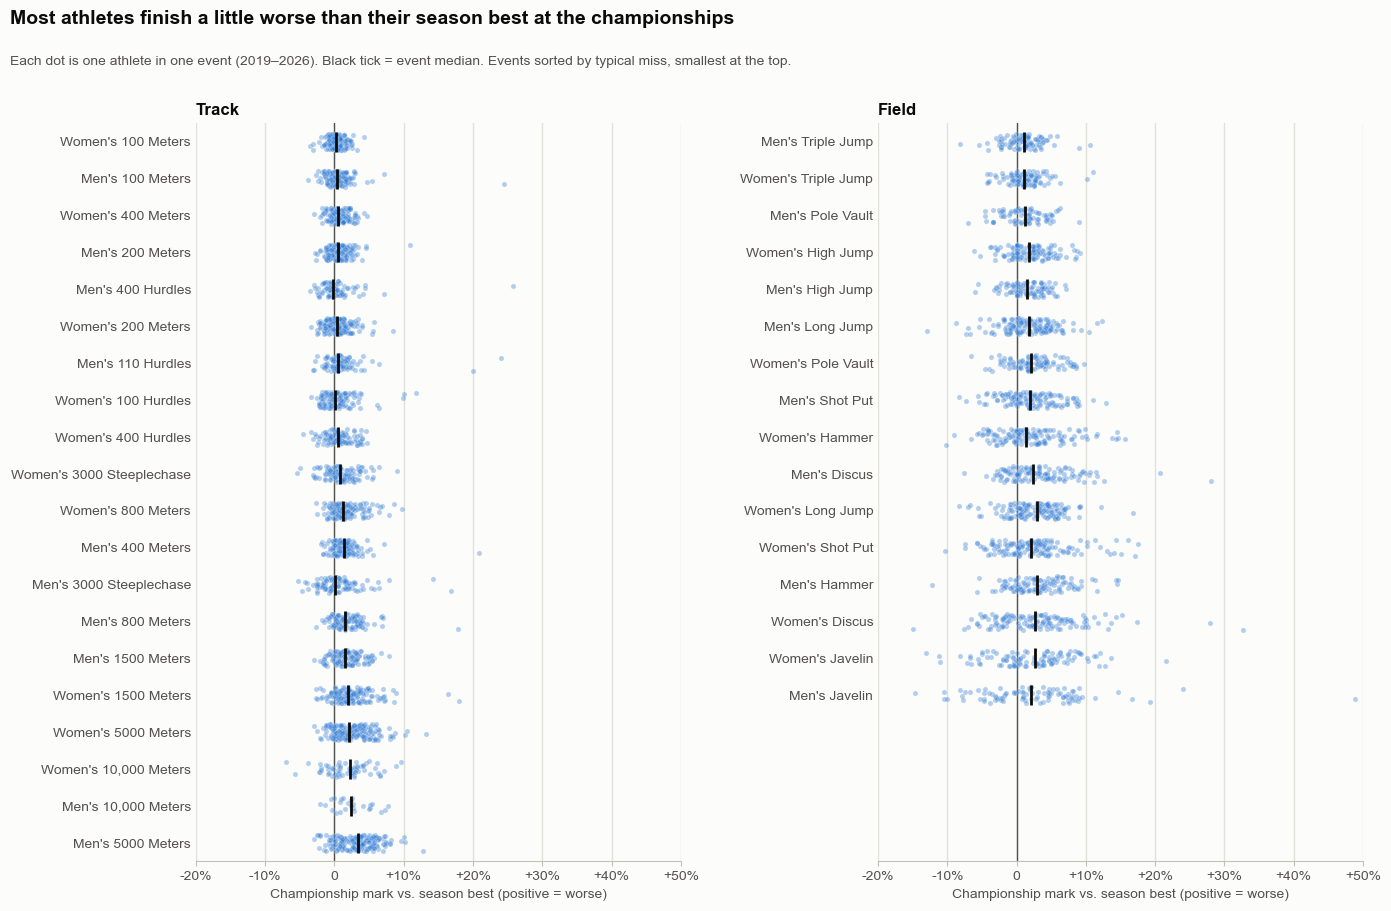

In [10]:
import matplotlib.pyplot as plt

INK, INK_2 = '#0b0b0b', '#52514e'
SURFACE, GRID, AXIS = '#fcfcfb', '#e1e0d9', '#c3c2b7'
DOT = '#2a78d6'

rng = np.random.default_rng(0)  # fixed jitter, so the plot is the same every run
panels = [('track', 'Track'), ('field', 'Field')]
max_rows = max(direct.loc[direct['event_type'] == t, 'event'].nunique() for t, _ in panels)
x_lo = np.floor(direct['pct_off_sb'].min() / 5) * 5
x_hi = np.ceil(direct['pct_off_sb'].max() / 5) * 5

style = {'font.family': ['Arial', 'DejaVu Sans'], 'font.size': 10,
         'axes.edgecolor': AXIS, 'xtick.color': AXIS, 'ytick.color': AXIS,
         'xtick.labelcolor': INK_2, 'ytick.labelcolor': INK_2}
with plt.rc_context(style):
    fig, axes = plt.subplots(1, 2, figsize=(14, 0.34 * max_rows + 2.4), facecolor=SURFACE)
    for ax, (event_type, title) in zip(axes, panels):
        df = direct[direct['event_type'] == event_type]
        order = per_event_direct.loc[event_type].sort_values('Typical miss (%)').index
        row = {event: i for i, event in enumerate(order)}
        y = df['event'].map(row) + rng.uniform(-0.22, 0.22, len(df))
        medians = df.groupby('event')['pct_off_sb'].median()

        ax.set_facecolor(SURFACE)
        ax.axvline(0, color=INK_2, linewidth=1, zorder=1)
        ax.scatter(df['pct_off_sb'], y, s=14, color=DOT, alpha=0.35,
                   edgecolors=SURFACE, linewidths=0.4, zorder=2)
        ax.scatter(medians.values, medians.index.map(row), marker='|', s=220,
                   color=INK, linewidths=2, zorder=3)

        ax.set_yticks(range(len(order)), order)
        ax.set_ylim(max_rows - 0.5, -0.5)
        ax.set_xlim(x_lo, x_hi)
        ax.xaxis.set_major_formatter(lambda v, _: f'{v:+.0f}%' if v else '0')
        ax.set_xlabel('Championship mark vs. season best (positive = worse)', color=INK_2)
        ax.grid(axis='x', color=GRID, linewidth=1)
        ax.set_axisbelow(True)
        ax.tick_params(axis='y', length=0)
        for side in ('top', 'right', 'left'):
            ax.spines[side].set_visible(False)
        ax.set_title(title, loc='left', color=INK, fontsize=12, fontweight='bold')

    fig.text(0.01, 0.985, 'Most athletes finish a little worse than their season best at the championships',
             color=INK, fontsize=14, fontweight='bold', va='top')
    fig.text(0.01, 0.935, f'Each dot is one athlete in one event ({TRAIN_YEARS[0]}–{TEST_YEAR}). '
             'Black tick = event median. Events sorted by typical miss, smallest at the top.',
             color=INK_2, fontsize=10, va='top')
    fig.tight_layout(rect=(0, 0, 1, 0.9), w_pad=3)
    plt.show()

### What this shows

- **Adding 2019 leaves the ranking unchanged.** On 2026: wind-legal season best 0.58 ≈ season best 0.58 > median 0.55 > mean of last 3 meets 0.54. Most recent meet is well behind at 0.39. Trained on 2021–2025 only, season best scored 0.59, so the extra year neither helps nor hurts.
- **No sign of overfitting:** the 2026 test score (0.58) is a little higher than the fit on 2019–2025 (0.55).
- **Weather from the regular-season model doesn't improve the predictions.** The weather-adjusted season best scores 0.55 on 2026 and the season-best line + weather shift 0.56, vs 0.58 without weather. Neither does better in the training years (both 0.54, vs 0.545). Field events are about the same; track gets slightly worse. Without any line fit, the weather-adjusted season best as-is does a bit better than the raw season best (0.349 vs 0.347 overall; field 0.52 vs 0.49; median per-event R² 0.54 vs 0.49).
- **Why so little:** the weather shift is small. Its spread between athletes is ~0.2–0.3%, while athletes typically miss their season best by ~1.7%. See the weather-only section below.
- **Fitting matters more than which feature.** Season best as-is scores 0.35 on 2026, vs 0.58 for the fitted season-best line. About 70% of athletes finish below their season best every year (median ~1.2% worse), and the line learns that drop-off. Half of the as-is error in 2026 is that consistent per-event offset.
- **The combined model (M4) is still the best on 2026 (0.60)**, just ahead of the per-event season-best line. It uses no weather and is still trained on 2021–2025.
- **Adding the weather shift to M4 makes it worse too:** 0.60 → 0.57 (track 0.57 → 0.53, field 0.64 → 0.63). It's worse in 25 of 35 events and better in 7. Even in distance events it's a wash (better in 4 of 9, median change 0.00).
- **Some years are harder than others.** Season best as-is ranges from 0.20 (2022, the hottest meet, when 81% of athletes finished below their season best) to 0.43 (2021). 2019 looks like 2021: median only 0.75% worse.
- **Weak spots:** women's 10,000m (11 athletes, negative for every predictor), men's 800m and men's 200m.

## Weather only: does championship weather predict Big West results?

A separate model that uses **only weather**: for each athlete, the regular-season model above predicts how much the move from their season-best meet's weather to the championship weather (temperature, precipitation, humidity) should change their mark. Nothing here is fit on championship results, so every championship, including 2026, is out of sample.

We compare that prediction with what actually happened, as **% worse than season best** (positive = worse), at two levels:
- **Athletes within the same event and year:** athletes whose season best came in friendlier weather should drop off more. We remove each event-year's average first, so this tests only the weather differences between athletes.
- **Meets:** does the average weather shift explain why some championships go worse than others? There are only 7, so this level can only show a rough pattern.

Team points aren't modeled: every Big West meet awards the same points in total, so weather can't change the total. It can only show up in the marks.

In [11]:
athletes = pd.concat([train, test], ignore_index=True)
athletes = athletes[athletes['event'].isin(train['event'])].copy()
ratio = athletes['final_mark'] / athletes['season_best']
athletes['pct_off_sb'] = np.where(athletes['event_type'] == 'track', ratio - 1, 1 - ratio) * 100
athletes['split'] = np.where(athletes['year'] == TEST_YEAR, TEST_LABEL, FIT_LABEL)

# Athlete level: remove each event-year's average from both, then compare
event_year = athletes.groupby(['year', 'event'])
athletes['actual_within'] = athletes['pct_off_sb'] - event_year['pct_off_sb'].transform('mean')
athletes['shift_within'] = athletes['wx_shift'] - event_year['wx_shift'].transform('mean')


def weather_fit(df):
    r, p = stats.pearsonr(df['shift_within'], df['actual_within'])
    slope = np.polyfit(df['shift_within'], df['actual_within'], 1)[0]
    return pd.Series({'athletes': len(df), 'SD of weather shift (%)': df['shift_within'].std(),
                      'r': r, 'p': p, 'R²': r ** 2, 'slope (1 = carries over fully)': slope})


rows = {}
for split in (FIT_LABEL, TEST_LABEL):
    df = athletes[athletes['split'] == split]
    rows[(split, 'All events')] = weather_fit(df)
    for group, g in df.groupby('group'):
        rows[(split, group)] = weather_fit(g)
athlete_level = pd.DataFrame(rows).T
print('Athlete level, within event-year: predicted weather shift vs actual % worse than season best')
display(athlete_level.round(3))

# Meet level: average predicted shift vs median actual drop-off, one row per championship
meet_level = athletes.groupby('year').agg(
    temp=('champ_temp', 'first'), precip_in=('champ_precip_in', 'first'), humidity_max=('champ_humidity_max', 'first'),
    predicted_shift=('wx_shift', 'mean'), actual_median=('pct_off_sb', 'median'))
for group, g in athletes.groupby('group'):
    meet_level[f'{group}: predicted'] = g.groupby('year')['wx_shift'].mean()
    meet_level[f'{group}: actual'] = g.groupby('year')['pct_off_sb'].median()
print('One row per championship (% worse than season best; predicted = weather shift only)')
display(meet_level.round(2))

rows = []
for name, pred_col, act_col in [('All events', 'predicted_shift', 'actual_median'),
                                *[(g, f'{g}: predicted', f'{g}: actual') for g in sorted(athletes['group'].unique())]]:
    r, p = stats.pearsonr(meet_level[pred_col], meet_level[act_col])
    rows.append({'group': name, 'r across 7 meets': r, 'p': p,
                 'predicted range': meet_level[pred_col].max() - meet_level[pred_col].min(),
                 'actual range': meet_level[act_col].max() - meet_level[act_col].min()})
print('Meet level: does the predicted weather shift track the actual drop-off? (n = 7, so p-values are rough)')
display(pd.DataFrame(rows).set_index('group').round(3))

Athlete level, within event-year: predicted weather shift vs actual % worse than season best


athletes  SD of weather shift (%)      r      p  \
2019–25 (fit) All events    3691.0                    0.228  0.047  0.004   
              Distance      1045.0                    0.229  0.065  0.035   
              Hurdles        340.0                    0.239  0.077  0.154   
              Jumps          747.0                    0.232  0.049  0.177   
              Sprints        750.0                    0.209 -0.001  0.969   
              Throws         809.0                    0.235  0.051  0.149   
2026 (test)   All events     698.0                    0.268 -0.022  0.555   
              Distance       186.0                    0.333  0.166  0.024   
              Hurdles         63.0                    0.237  0.010  0.940   
              Jumps          125.0                    0.189  0.014  0.878   
              Sprints        167.0                    0.219 -0.006  0.941   
              Throws         157.0                    0.298 -0.148  0.065   

                             R²  slope (1 = carries over fully)  
2019–25 (fit) All events  0.002                           0.692  
              Distance    0.004                           0.695  
              Hurdles     0.006                           0.894  
              Jumps       0.002                           0.651  
              Sprints     0.000                          -0.012  
              Throws      0.003                           1.157  
2026 (test)   All events  0.000                          -0.226  
              Distance    0.027                           0.868  
              Hurdles     0.000                           0.078  
              Jumps       0.000                           0.219  
              Sprints     0.000                          -0.031  
              Throws      0.022                          -2.177

One row per championship (% worse than season best; predicted = weather shift only)


,temp,precip_in,humidity_max,predicted_shift,actual_median,Distance: predicted,Distance: actual,Hurdles: predicted,Hurdles: actual,Jumps: predicted,Jumps: actual,Sprints: predicted,Sprints: actual,Throws: predicted,Throws: actual
year,,,,,,,,,,,,,,,
2019,68.3,0.02,91.5,0.09,0.75,-0.02,1.00,0.24,0.07,0.15,0.84,0.14,0.47,0.07,2.00
2021,70.1,0.02,89.2,-0.11,0.76,-0.30,0.43,-0.02,0.28,-0.08,1.67,0.08,0.63,-0.11,1.63
2022,89.8,0.00,87.5,0.09,1.73,0.97,2.27,-0.43,0.37,-0.56,1.91,-0.33,1.22,0.07,3.89
2023,75.6,0.00,98.5,-0.11,1.12,-0.20,1.95,-0.02,0.41,-0.18,1.62,0.00,0.59,-0.09,1.11
2024,75.2,0.00,95.5,-0.14,1.19,-0.09,1.68,-0.17,0.36,-0.25,1.23,-0.11,0.51,-0.14,2.80
2025,65.2,0.04,88.0,0.06,1.24,-0.06,1.82,0.14,0.18,0.11,1.82,0.08,0.28,0.11,2.59
2026,68.1,0.00,89.0,0.20,1.21,-0.02,2.49,0.33,0.06,0.35,1.46,0.27,0.16,0.20,2.34


Meet level: does the predicted weather shift track the actual drop-off? (n = 7, so p-values are rough)


,r across 7 meets,p,predicted range,actual range
group,,,,
All events,0.291,0.527,0.337,0.982
Distance,0.482,0.273,1.261,2.057
Hurdles,-0.843,0.017,0.765,0.357
Jumps,-0.413,0.357,0.913,1.070
Sprints,-0.894,0.007,0.601,1.057
Throws,0.347,0.446,0.340,2.783


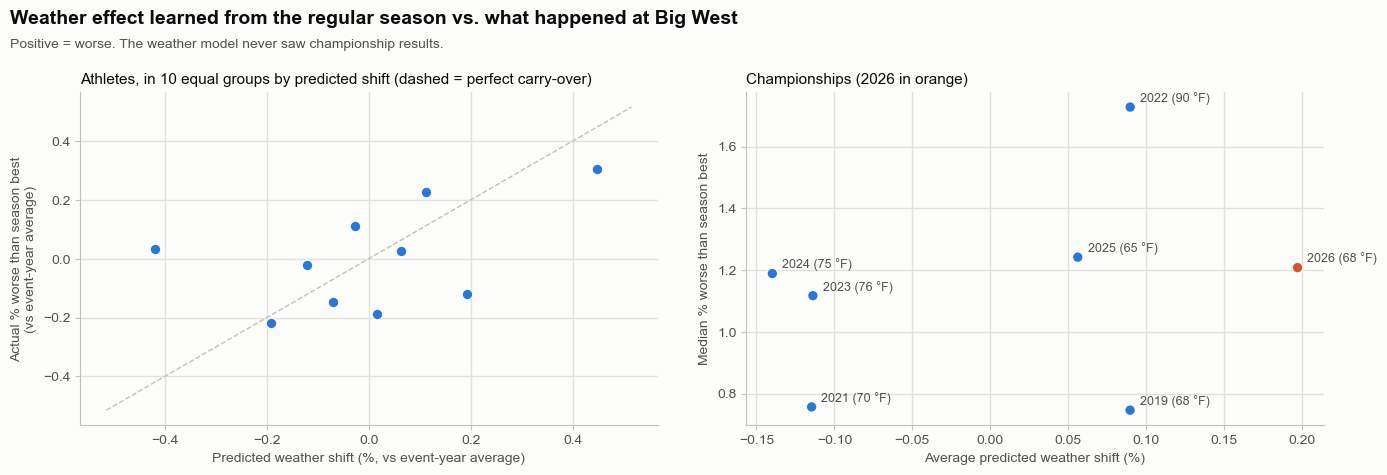

In [12]:
TEST_DOT = '#d6542a'
with plt.rc_context(style):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), facecolor=SURFACE)

    # Left: athletes, binned by predicted weather shift (within event-year)
    ax = axes[0]
    df = athletes.copy()
    df['bin'] = pd.qcut(df['shift_within'], 10, duplicates='drop')
    binned = df.groupby('bin', observed=True)[['shift_within', 'actual_within']].mean()
    lim = np.abs(binned.to_numpy()).max() * 1.15
    ax.plot([-lim, lim], [-lim, lim], color=AXIS, linewidth=1, linestyle='--', zorder=1)
    ax.scatter(binned['shift_within'], binned['actual_within'], s=60, color=DOT,
               edgecolors=SURFACE, linewidths=1, zorder=2)
    ax.set_xlabel('Predicted weather shift (%, vs event-year average)', color=INK_2)
    ax.set_ylabel('Actual % worse than season best\n(vs event-year average)', color=INK_2)
    ax.set_title('Athletes, in 10 equal groups by predicted shift (dashed = perfect carry-over)',
                 loc='left', color=INK, fontsize=11)

    # Right: one dot per championship
    ax = axes[1]
    x, y = meet_level['predicted_shift'], meet_level['actual_median']
    colors = [TEST_DOT if yr == TEST_YEAR else DOT for yr in meet_level.index]
    ax.scatter(x, y, s=60, color=colors, edgecolors=SURFACE, linewidths=1, zorder=2)
    for yr in meet_level.index:
        ax.annotate(f"{yr} ({meet_level.loc[yr, 'temp']:.0f} °F)", (x[yr], y[yr]), xytext=(7, 4),
                    textcoords='offset points', fontsize=9, color=INK_2)
    ax.set_xlabel('Average predicted weather shift (%)', color=INK_2)
    ax.set_ylabel('Median % worse than season best', color=INK_2)
    ax.set_title(f'Championships ({TEST_YEAR} in orange)', loc='left', color=INK, fontsize=11)

    for ax in axes:
        ax.set_facecolor(SURFACE)
        ax.grid(color=GRID, linewidth=1)
        ax.set_axisbelow(True)
        for side in ('top', 'right'):
            ax.spines[side].set_visible(False)
    fig.text(0.01, 0.98, 'Weather effect learned from the regular season vs. what happened at Big West',
             color=INK, fontsize=14, fontweight='bold', va='top')
    fig.text(0.01, 0.92, 'Positive = worse. The weather model never saw championship results.',
             color=INK_2, fontsize=10, va='top')
    fig.tight_layout(rect=(0, 0, 1, 0.88), w_pad=3)
    plt.show()

### What the weather-only model shows

**Weather explains almost nothing about Big West results overall. The exception is distance runners in heat.**

**What the regular season says** (25,000+ marks, each athlete compared with themselves): weather matters, but differently by event group.
- **Distance** runners are ~0.9% worse above 85 °F (p < 0.001).
- **Sprinters, hurdlers and jumpers** are 0.5–0.8% *better* above 85 °F.
- **Rain and humidity** barely matter (under 0.1% per step).

**Does it carry over to the championships?**
- **Athletes within the same event and year:** overall, no. The predicted weather shift explains 0.2% of the variation in the training years and 0% in 2026. Differences in weather between athletes are small: the shift's spread is about 0.2–0.3%, while athletes typically miss their season best by about 1.7%.
- **Distance is the exception, and it holds up out of sample.** r = 0.07 (p = 0.035) in 2019–2025 and r = 0.17 (p = 0.02) in 2026. The slope is 0.7–0.9, so most of the regular-season heat effect shows up at the championships. Sprints show nothing; hurdles, jumps and throws are inconsistent between the training years and 2026.
- **Across the 7 meets:** the average predicted shift barely tracks the overall drop-off (r = 0.29, p = 0.53). Distance goes the expected way (r = 0.48): 2022 at 90 °F has the largest predicted penalty (+0.97%) and one of the worst actual medians (2.27%). Sprints and hurdles go the *opposite* way (r = −0.89 and −0.84). The regular season says heat should have helped them in 2022, but they had their worst meet. So 2022 wasn't mainly about heat, or championship heat differs from a hot regular-season meet (two days of rounds, timing in the day).
- **2026 wasn't about weather either.** It had the largest predicted shift (+0.20%, because many season bests came on 60–70 °F days), but an ordinary actual drop-off (1.21%).

**Bottom line:** the regular season is the right place to learn the weather effect, and the effect is real there. But it's small next to everything else that happens at a championship. For predicting marks, only the distance heat effect looks worth keeping.